In [ ]:
!pip install -q kagglehub

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

Download and load the tables

In [ ]:
path = kagglehub.dataset_download("anlgrbz/student-demographics-online-education-dataoulad")
print("Files:", os.listdir(path))

def read(name):

    for f in os.listdir(path):
        if f.lower() == f"{name.lower()}.csv":
            return pd.read_csv(os.path.join(path, f))
    raise FileNotFoundError(name)

student_info   = read("studentInfo")
registration   = read("studentRegistration")
assessments    = read("assessments")
student_assess = read("studentAssessment")
student_vle    = read("studentVle")
vle            = read("vle")
courses        = read("courses")

for n, d in {"studentInfo": student_info, "studentRegistration": registration,
             "assessments": assessments, "studentAssessment": student_assess,
             "studentVle": student_vle, "vle": vle, "courses": courses}.items():
    print(f"{n:20s} {d.shape}")

100%|██████████| 42.2M/42.2M [00:00<00:00, 44.4MB/s]

Extracting files...


Files: ['studentInfo.csv', 'courses.csv', 'assessments.csv', 'studentVle.csv', 'vle.csv', 'studentRegistration.csv', 'studentAssessment.csv']
studentInfo          (32593, 12)
studentRegistration  (32593, 5)
assessments          (206, 6)
studentAssessment    (173912, 5)
studentVle           (10655280, 6)
vle                  (6364, 6)
courses              (22, 3)


### Project overview

**Question:** Using only the first four weeks of data, can we tell which online students will fail or withdraw?

**Data:** Open University Learning Analytics Dataset (OULAD), a Kaggle copy of the original release (Kuzilek, Hlosta & Zdrahal, 2017). It covers 32,593 students in 7 courses, with about 10.6 million rows of website clicks. The license is CC BY 4.0.

The seven tables load here. They link to each other through the student ID, the course (module) and the course run (presentation).

**Plan:** (1) look at the data, (2) build features from the first 28 days, (3) train and tune three traditional models, (4) build a neural network with the Keras Functional API, (5) run experiments, (6) look at what drives the results and who the tool misses, (7) save the models.

Inspect studentInfo and the class balance

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

Final result counts:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

At-risk share: 0.528


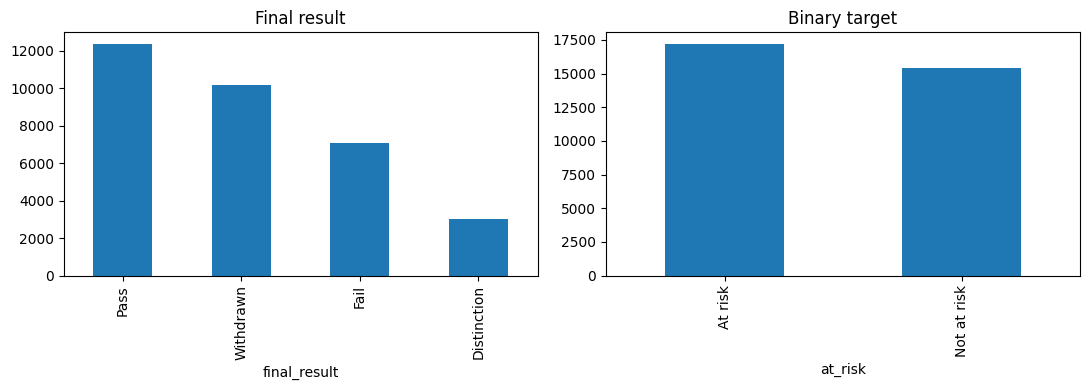

In [ ]:
display(student_info.head())
print(student_info.isna().sum())

print("\nFinal result counts:")
print(student_info["final_result"].value_counts())

student_info["at_risk"] = student_info["final_result"].isin(["Withdrawn", "Fail"]).astype(int)
print("\nAt-risk share:", student_info["at_risk"].mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
student_info["final_result"].value_counts().plot(kind="bar", ax=ax[0], title="Final result")
student_info["at_risk"].value_counts().rename({0: "Not at risk", 1: "At risk"}).plot(
    kind="bar", ax=ax[1], title="Binary target")
plt.tight_layout(); plt.show()

### The target

Every student ends with one of four results: Distinction, Pass, Fail or Withdrawn. We make one yes-or-no target. A student is at risk (1) if the result is Withdrawn or Fail. A student is not at risk (0) if the result is Pass or Distinction.

The bar charts above show the four results and the two groups.

cohort and settings

In [ ]:
KEYS = ["code_module", "code_presentation", "id_student"]
CUTOFF_DAY = 28
N_WEEKS = CUTOFF_DAY // 7

reg = registration[KEYS + ["date_registration", "date_unregistration"]]
base = student_info.merge(reg, on=KEYS, how="left")

n_before = len(base)
base = base[~(base["date_unregistration"] <= CUTOFF_DAY)].copy()
print(f"Removed {n_before - len(base)} students who unregistered by day {CUTOFF_DAY}")
print("Cohort size:", len(base), "| at-risk share:", base["at_risk"].mean().round(3))

base = base.drop(columns=["date_unregistration"])

Removed 5055 students who unregistered by day 28
Cohort size: 27538 | at-risk share: 0.441


### Prediction day and cohort

We predict on **day 28**, the end of week 4. A tool cannot help a student who has already left, so we remove the **5,055** students who unregistered on or before day 28. That leaves **27,538** students. Of these, **44.1%** end up at risk.

We then drop the unregistration date. It is only filled in for students who left, so keeping it would give the answer away (this is called data leakage).

VLE click features (first N weeks only)

In [ ]:
sv = student_vle[student_vle["date"] <= CUTOFF_DAY].merge(
    vle[["id_site", "code_module", "code_presentation", "activity_type"]],
    on=["id_site", "code_module", "code_presentation"], how="left")

agg = sv.groupby(KEYS).agg(total_clicks=("sum_click", "sum"),
                           active_days=("date", "nunique"),
                           distinct_sites=("id_site", "nunique"))

pre = sv[sv["date"] < 0].groupby(KEYS)["sum_click"].sum().rename("pre_start_clicks")

wk = sv[sv["date"] >= 0].copy()
wk["week"] = (wk["date"] // 7).clip(upper=N_WEEKS - 1).astype(int)
weekly = wk.pivot_table(index=KEYS, columns="week", values="sum_click",
                        aggfunc="sum", fill_value=0)
weekly.columns = [f"clicks_wk{c + 1}" for c in weekly.columns]

top_act = sv.groupby("activity_type")["sum_click"].sum().nlargest(6).index
act = (sv[sv["activity_type"].isin(top_act)]
       .pivot_table(index=KEYS, columns="activity_type", values="sum_click",
                    aggfunc="sum", fill_value=0))
act.columns = [f"act_{c}" for c in act.columns]

vle_feats = agg.join([pre, weekly, act], how="left").reset_index()
print(vle_feats.shape)

(28792, 17)


### Website activity features

Here we keep only clicks from day 28 or earlier and build these columns for each student: total clicks, active days, number of different pages used, clicks before the course started, clicks in each of weeks 1 to 4, and clicks on the six most used activity types.

Early assessments, merge and save

In [ ]:
sa = student_assess.merge(
    assessments[["id_assessment", "code_module", "code_presentation"]],
    on="id_assessment", how="left")
sa = sa[sa["date_submitted"] <= CUTOFF_DAY]
assess_feats = (sa.groupby(KEYS)
                  .agg(n_submitted=("id_assessment", "count"),
                       mean_score=("score", "mean"))
                  .reset_index())

df = (base.merge(vle_feats, on=KEYS, how="left")
          .merge(assess_feats, on=KEYS, how="left"))

zero_cols = [c for c in df.columns if c.startswith(("clicks_wk", "act_"))] + \
            ["total_clicks", "active_days", "distinct_sites", "pre_start_clicks", "n_submitted"]
df[zero_cols] = df[zero_cols].fillna(0)

print("Final table:", df.shape)
print("At-risk share:", df["at_risk"].mean().round(3))
display(df.head())
print(df.isna().sum()[lambda s: s > 0])

df.to_csv("oulad_features.csv", index=False)

Final table: (27538, 30)
At-risk share: 0.441


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,total_clicks,active_days,distinct_sites,pre_start_clicks,clicks_wk1,clicks_wk2,clicks_wk3,clicks_wk4,act_forumng,act_homepage,act_oucontent,act_quiz,act_resource,act_subpage,n_submitted,mean_score
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0,-159.0,401.0,8.0,24.0,98.0,183.0,20.0,100.0,0.0,55.0,42.0,273.0,0.0,9.0,21.0,1.0,78.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0,-53.0,618.0,19.0,34.0,215.0,175.0,66.0,37.0,125.0,209.0,132.0,183.0,0.0,5.0,59.0,1.0,70.0
2,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0,-52.0,494.0,22.0,31.0,169.0,22.0,154.0,108.0,41.0,131.0,95.0,188.0,0.0,10.0,52.0,1.0,72.0
3,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0,-176.0,567.0,24.0,34.0,295.0,61.0,116.0,37.0,58.0,138.0,102.0,284.0,0.0,7.0,28.0,1.0,69.0
4,AAA,2013J,38053,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass,0,-110.0,727.0,32.0,30.0,277.0,135.0,141.0,135.0,39.0,341.0,174.0,164.0,0.0,6.0,31.0,1.0,79.0


imd_band             1028
date_registration       7
mean_score           7136
dtype: int64


### Early assignments and the final table

We add two assignment features: how many assignments the student handed in by day 28 and the average score. Students who handed in nothing get 0 submitted and a missing score.

We then join everything into one table with one row per student and course run. Missing values are: average score for 7,136 students (nothing handed in yet), deprivation band for 1,028 students and registration date for 7. We fill these gaps later. The table is saved as `oulad_features.csv`.

Overall at-risk rate: 0.441

Breakdown of final_result:
final_result
Pass           0.449
Fail           0.256
Withdrawn      0.186
Distinction    0.110
Name: proportion, dtype: float64


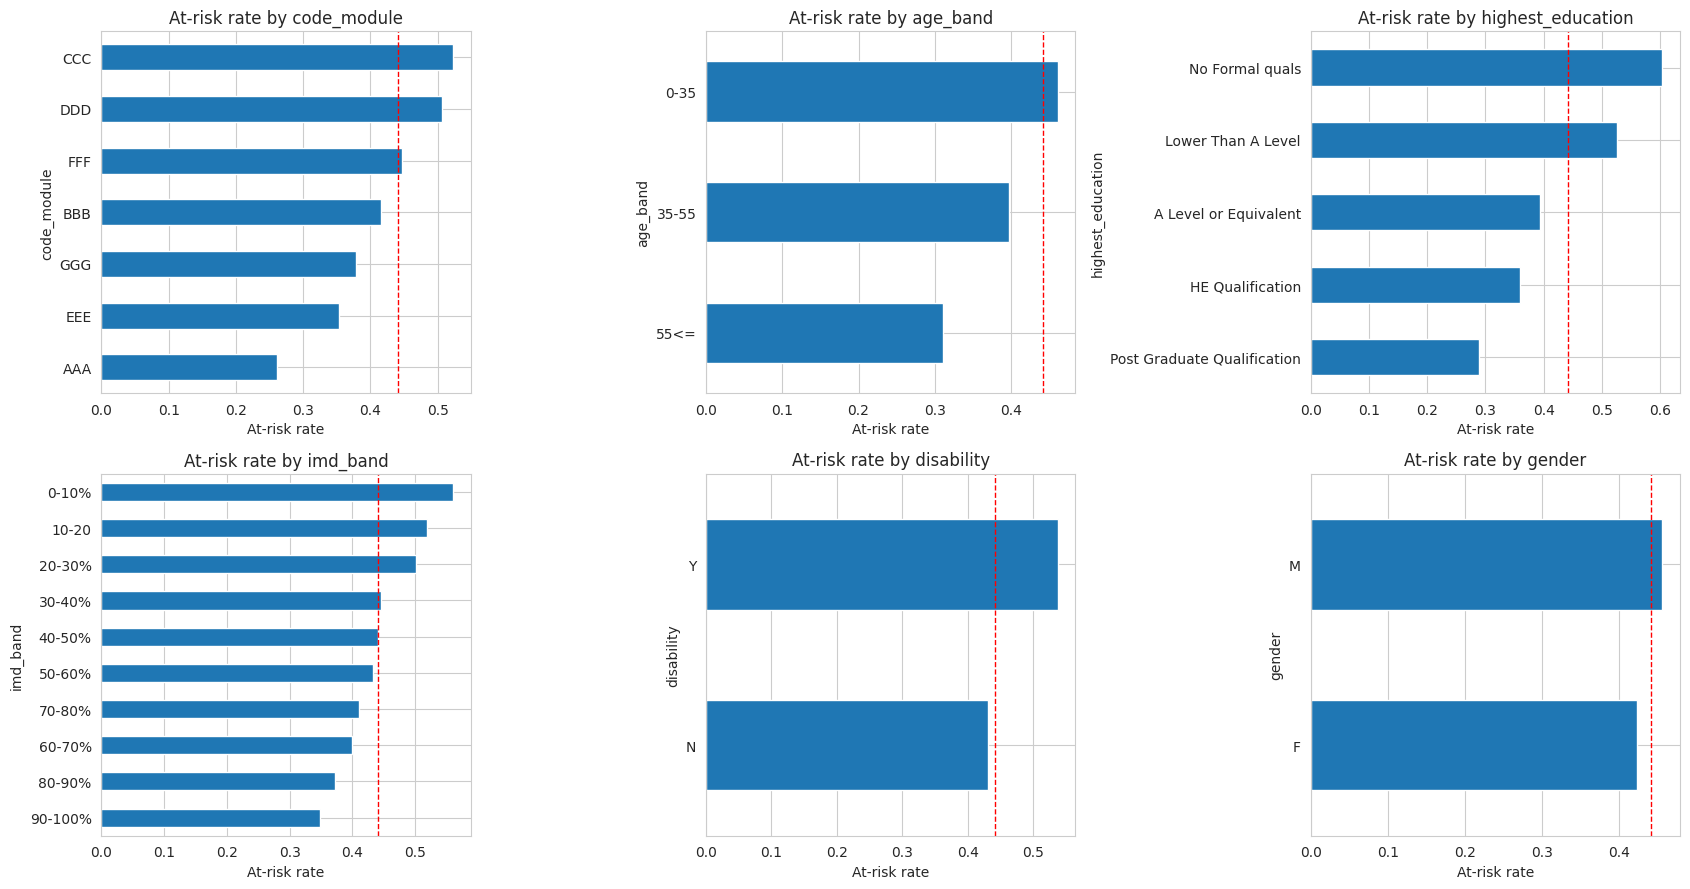

In [ ]:
import seaborn as sns
sns.set_style("whitegrid")

print("Overall at-risk rate:", df["at_risk"].mean().round(3))
print("\nBreakdown of final_result:")
print(df["final_result"].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(),
                   ["code_module", "age_band", "highest_education",
                    "imd_band", "disability", "gender"]):
    rate = df.groupby(col)["at_risk"].mean().sort_values()
    rate.plot(kind="barh", ax=ax, title=f"At-risk rate by {col}")
    ax.axvline(df["at_risk"].mean(), color="red", ls="--", lw=1)
    ax.set_xlabel("At-risk rate")
plt.tight_layout(); plt.show()

### Who is at risk?

The red dashed line is the overall at-risk rate (44.1%). Risk differs by group:

- **Course:** lowest in AAA and highest in CCC and DDD.
- **Age:** higher for students aged 0 to 35.
- **Education:** highest for students with no formal qualifications and lowest for postgraduates.
- **Deprivation (IMD):** higher in the most deprived areas.
- **Disability:** higher for students with a disability.
- **Gender:** a small difference.

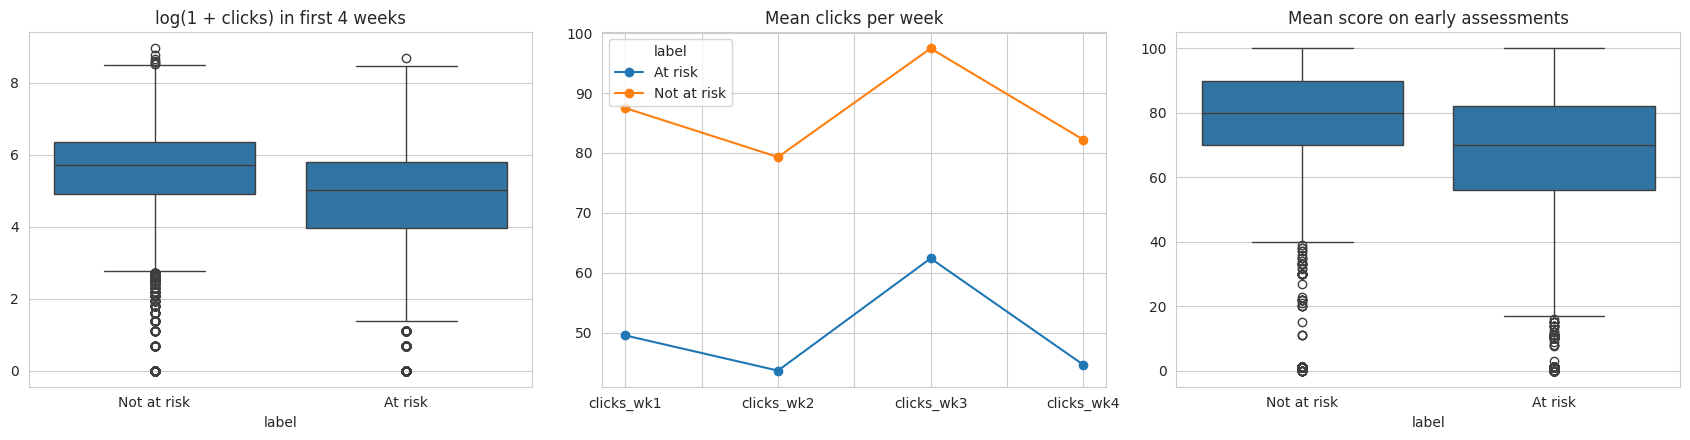

Share with zero clicks:
 label
At risk        0.062
Not at risk    0.011
Name: total_clicks, dtype: float64

Share with no submitted assessment:
 label
At risk        0.325
Not at risk    0.206
Name: n_submitted, dtype: float64

Median total clicks:
 label
At risk        152.0
Not at risk    298.0
Name: total_clicks, dtype: float64


In [ ]:
df["label"] = df["at_risk"].map({0: "Not at risk", 1: "At risk"})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=df, x="label", y=np.log1p(df["total_clicks"]), ax=axes[0])
axes[0].set_title(f"log(1 + clicks) in first {N_WEEKS} weeks"); axes[0].set_ylabel("")

wk_cols = [f"clicks_wk{i}" for i in range(1, N_WEEKS + 1)]
df.groupby("label")[wk_cols].mean().T.plot(marker="o", ax=axes[1],
                                           title="Mean clicks per week")

sns.boxplot(data=df, x="label", y="mean_score", ax=axes[2])
axes[2].set_title("Mean score on early assessments"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

print("Share with zero clicks:\n", df.groupby("label")["total_clicks"].apply(lambda s: (s == 0).mean()).round(3))
print("\nShare with no submitted assessment:\n", df.groupby("label")["n_submitted"].apply(lambda s: (s == 0).mean()).round(3))
print("\nMedian total clicks:\n", df.groupby("label")["total_clicks"].median())

### Does early behavior separate the groups?

Yes. At-risk students have much lower activity in every one of the first four weeks. Their median total clicks are **152**, against **298** for students who are not at risk. They are also about six times as likely to have no clicks at all (**6.2%** vs **1.1%**). **32.5%** of at-risk students handed in nothing by week 4, against **20.6%** of the others. Among those who handed work in, at-risk students scored lower.

imd_band             1028
date_registration       7
mean_score           7136
dtype: int64


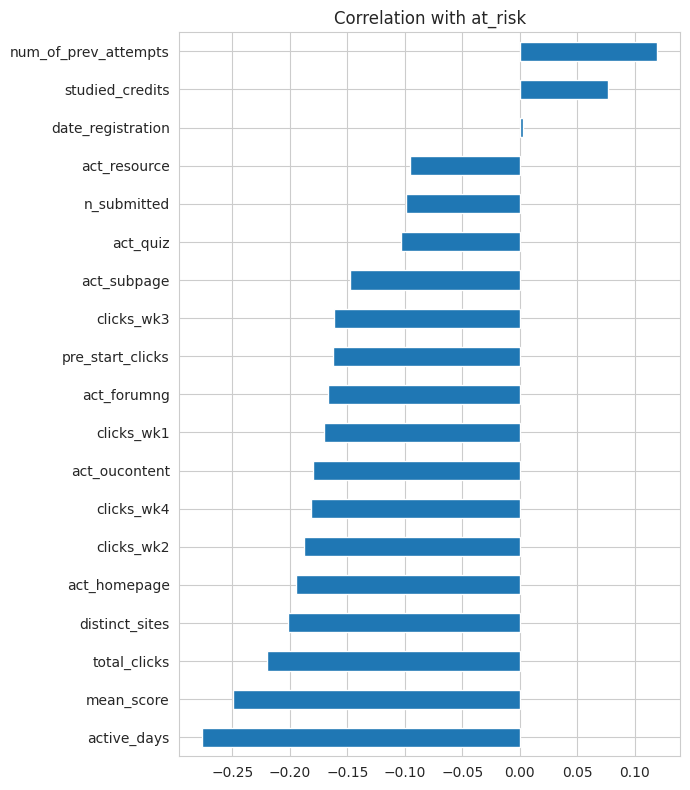

In [ ]:
print(df.isna().sum()[lambda s: s > 0])

num = df.select_dtypes("number").drop(columns=["id_student"])
corr = num.corr()["at_risk"].drop("at_risk").sort_values()
corr.plot(kind="barh", figsize=(7, 8), title="Correlation with at_risk")
plt.tight_layout(); plt.show()

### Links with risk

The strongest links with being at risk are active days (about -0.27), average score (-0.25), total clicks (-0.22) and different pages used (-0.20). More earlier attempts (+0.12) and more credits studied (+0.08) go with higher risk. A link is not a cause.

features, grouped split, preprocessing

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

data = df.drop(columns=["final_result", "label"]).copy()
data["no_submission"] = (data["n_submitted"] == 0).astype(int)

# Heavily skewed count features -> log scale
click_cols = [c for c in data.columns if c.startswith(("clicks_wk", "act_"))] + \
             ["total_clicks", "pre_start_clicks", "distinct_sites"]
data[click_cols] = np.log1p(data[click_cols])

y = data["at_risk"]
groups = data["id_student"]
X = data.drop(columns=["at_risk", "id_student"])

# Split by student so the same person never appears in both train and test
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("At-risk share  train:", y_train.mean().round(3), " test:", y_test.mean().round(3))

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print("Categorical:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

Train: (21962, 28) | Test: (5576, 28)
At-risk share  train: 0.438  test: 0.455
Categorical: ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']


### Split and preparation

- **Split:** 80% training (21,962 students) and 20% test (5,576 students). We split by student ID so the same person is never in both sets. The at-risk share is 43.8% in training and 45.5% in the test set.
- **Log transform:** click counts are very uneven, so we use log(1 + x).
- **Gaps and scaling:** missing numbers get the median. Categories become 0/1 columns. Numbers are scaled to a common size. This gives the 67 inputs used by the linear model and the neural network.

The test set stays untouched until each model is finished.

evaluation helper

In [ ]:
results = []

def evaluate(name, model, X_te=None, y_te=None):
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    row = {"model": name,
           "accuracy": accuracy_score(y_te, pred),
           "precision": precision_score(y_te, pred),
           "recall": recall_score(y_te, pred),
           "f1": f1_score(y_te, pred),
           "roc_auc": roc_auc_score(y_te, proba)}
    results.append(row)
    print(pd.Series(row).round(3).to_string())
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                           display_labels=["Not at risk", "At risk"]).plot(cmap="Blues")
    plt.title(name); plt.show()

### Evaluation helper

This function scores a model on the test set (accuracy, precision, recall, F1 and ROC-AUC), stores the scores in the `results` list and draws the confusion matrix. Every model below uses it, so the scores can be compared fairly.

baseline logistic regression

model        Logistic Regression (baseline)
accuracy                           0.723637
precision                          0.743052
recall                             0.600473
f1                                 0.664197
roc_auc                            0.788827


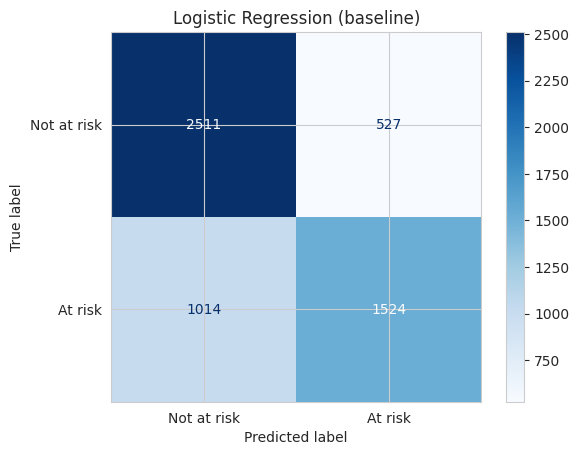

In [ ]:
logreg = Pipeline([("prep", preprocess),
                   ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
logreg.fit(X_train, y_train)
evaluate("Logistic Regression (baseline)", logreg)

### Baseline model

Logistic regression adds up weighted evidence. It is simple, so it is a good baseline. It gets accuracy 0.724, recall 0.600 and ROC-AUC 0.789.

How to read the scores: **precision** is how many flagged students really are at risk. **Recall** is how many at-risk students we catch. **ROC-AUC** is how well the model ranks at-risk students above the others (0.5 is guessing, 1.0 is perfect). The confusion matrix shows 1,014 at-risk students missed and 527 false alarms.

Tree preprocessing and Random Forest

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best params: {'clf__n_estimators': 400, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.3, 'clf__max_depth': 16}
Best CV AUC: 0.7772
model        Random Forest (tuned)
accuracy                  0.725789
precision                 0.751621
recall                    0.593775
f1                        0.663438
roc_auc                   0.789637


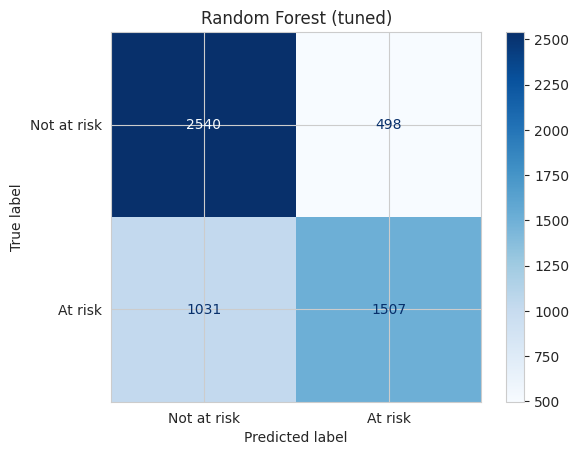

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

groups_train = groups.iloc[train_idx]
cv = GroupKFold(n_splits=3)

preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("ord", OrdinalEncoder(handle_unknown="use_encoded_value",
                                             unknown_value=-1))]), cat_cols),
])

rf = Pipeline([("prep", preprocess_tree),
               ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

rf_params = {
    "clf__n_estimators": [200, 400, 600],
    "clf__max_depth": [8, 12, 16, None],
    "clf__min_samples_leaf": [1, 3, 5, 10],
    "clf__max_features": ["sqrt", 0.3, 0.5],
}
rf_search = RandomizedSearchCV(rf, rf_params, n_iter=15, cv=cv, scoring="roc_auc",
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
rf_search.fit(X_train, y_train, groups=groups_train)

print("Best params:", rf_search.best_params_)
print("Best CV AUC:", round(rf_search.best_score_, 4))
evaluate("Random Forest (tuned)", rf_search.best_estimator_)

### Random forest

A random forest is many decision trees that vote. We tried 15 settings with 3-fold cross-validation grouped by student. The best used 400 trees, depth 16, a minimum leaf size of 10 and 0.3 of the features per split. Cross-validation AUC was 0.777 and test AUC was 0.790, so it did not overfit.

Gradient Boosting

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best params: {'clf__min_samples_leaf': 50, 'clf__max_iter': 600, 'clf__max_depth': 5, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 0.1}
Best CV AUC: 0.7817
model        Gradient Boosting (tuned)
accuracy                      0.727044
precision                     0.744466
recall                        0.609535
f1                            0.670277
roc_auc                       0.796725


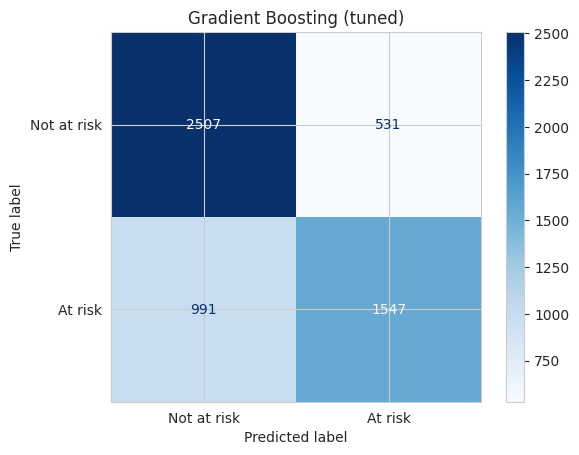

In [ ]:
hgb = Pipeline([("prep", preprocess_tree),
                ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE,
                                                       early_stopping=True))])

hgb_params = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_iter": [200, 400, 600],
    "clf__max_depth": [3, 5, 7, None],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
}
hgb_search = RandomizedSearchCV(hgb, hgb_params, n_iter=15, cv=cv, scoring="roc_auc",
                                random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
hgb_search.fit(X_train, y_train, groups=groups_train)

print("Best params:", hgb_search.best_params_)
print("Best CV AUC:", round(hgb_search.best_score_, 4))
evaluate("Gradient Boosting (tuned)", hgb_search.best_estimator_)

### Gradient boosting

Gradient boosting builds trees one after another, and each tree fixes the mistakes of the last. The best settings were learning rate 0.03, depth 5, 600 rounds, minimum leaf size 50 and an L2 penalty of 0.1. Cross-validation AUC was 0.782. On the test set it scored AUC 0.797 and recall 0.610, the best of the three.

comparison table

In [ ]:
comparison = pd.DataFrame(results).set_index("model").round(3)
display(comparison)
comparison.to_csv("traditional_model_results.csv")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression (baseline),0.724,0.743,0.600,0.664,0.789
Random Forest (tuned),0.726,0.752,0.594,0.663,0.790
Gradient Boosting (tuned),0.727,0.744,0.610,0.670,0.797


### Traditional models compared

The three models are very close. Gradient boosting is only slightly ahead. A simple linear model is almost as good as the tuned tree models. This hints that the limit comes from the information in the first four weeks, not from the choice of model.

prepare arrays

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
tf.random.set_seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
tr_i, va_i = next(gss_val.split(X_train, y_train, groups_train))

prep_nn = preprocess.fit(X_train.iloc[tr_i])
Xtr = prep_nn.transform(X_train.iloc[tr_i]); ytr = y_train.iloc[tr_i].values
Xva = prep_nn.transform(X_train.iloc[va_i]); yva = y_train.iloc[va_i].values
Xte = prep_nn.transform(X_test);            yte = y_test.values
Xtr, Xva, Xte = [m.toarray() if hasattr(m, "toarray") else m for m in (Xtr, Xva, Xte)]
print(Xtr.shape, Xva.shape, Xte.shape)

(18647, 67) (3315, 67) (5576, 67)


### Data for the neural network

We hold out 15% of the training students as a validation set, split by student. The preprocessing is fit on the remaining training students only, so no validation or test information leaks in. The result is 18,647 training rows, 3,315 validation rows and 5,576 test rows, each with 67 inputs.

Functional API model builder

In [ ]:
def build_model(input_dim, units=64, dropout=0.3, lr=1e-3, l2=1e-4):
    inp = keras.Input(shape=(input_dim,), name="features")
    x = layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(units // 2, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(units // 4, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid", name="at_risk")(x)
    model = keras.Model(inp, out, name="early_warning_nn")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

build_model(Xtr.shape[1]).summary()

Model: "early_warning_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 67)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ at_risk (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,233 (28.25 KB)

 Trainable params: 7,105 (27.75 KB)

 Non-trainable params: 128 (512.00 B)

### Neural network design

The network takes the 67 inputs. It has three dense layers (units, units/2, units/4) with ReLU, a batch normalization layer, two dropout layers and L2 penalties. The output is one number between 0 and 1: the chance that the student is at risk. We train with Adam and binary cross-entropy and stop early when the validation AUC stops improving.

small hyperparameter search

In [ ]:
import itertools, time
grid = list(itertools.product([32, 64, 128],
                              [0.2, 0.4],
                              [1e-3, 3e-4]))
es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8,
                                   restore_best_weights=True)
tune_rows, histories = [], {}
for units, dr, lr in grid:
    t0 = time.time()
    m = build_model(Xtr.shape[1], units, dr, lr)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=60, batch_size=256,
              callbacks=[es], verbose=0)
    best = max(h.history["val_auc"])
    tune_rows.append({"units": units, "dropout": dr, "lr": lr,
                      "val_auc": round(best, 4), "epochs": len(h.history["val_auc"]),
                      "secs": round(time.time() - t0)})
    histories[(units, dr, lr)] = h

tune_df = pd.DataFrame(tune_rows).sort_values("val_auc", ascending=False)
display(tune_df)
tune_df.to_csv("nn_tuning_results.csv", index=False)

,units,dropout,lr,val_auc,epochs,secs
8,128,0.2,0.0010,0.7767,23,19
4,64,0.2,0.0010,0.7751,21,13
10,128,0.4,0.0010,0.7714,8,9
0,32,0.2,0.0010,0.7708,29,15
6,64,0.4,0.0010,0.7614,8,8
9,128,0.2,0.0003,0.7602,8,8
11,128,0.4,0.0003,0.7567,8,8
5,64,0.2,0.0003,0.7524,8,6
2,32,0.4,0.0010,0.7494,8,6
7,64,0.4,0.0003,0.7235,8,6


### Note: first attempt, replaced below

This first run reused one early-stopping object for every setting. It remembered the best score from the first run, so it cut the later runs short at 8 epochs, while they were still improving. The scores here (for example AUC about 0.707) are therefore too low and are **not used in the report**. We kept the cells so the work is easy to follow. The corrected runs come further down, starting with the cell that defines `make_es`.

train the best configuration and evaluat

Best config (units, dropout, lr): (128, 0.2, 0.001)


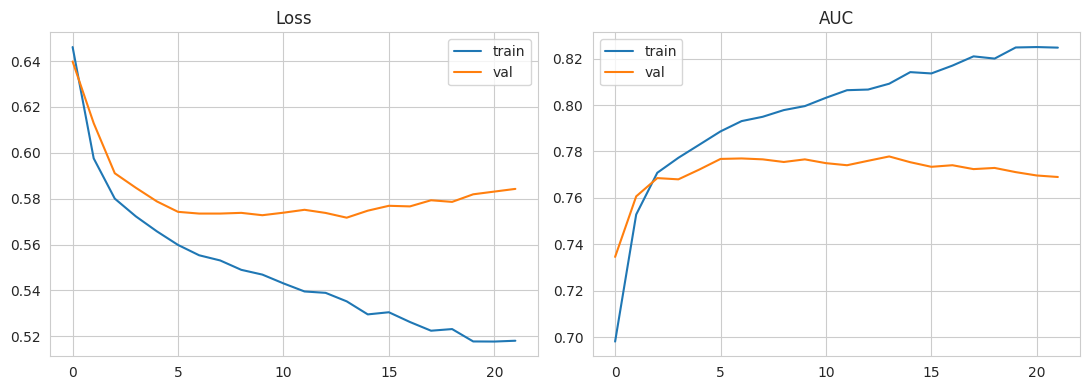

model        Neural Network (Keras Functional API)
accuracy                                  0.721126
precision                                  0.73528
recall                                    0.605201
f1                                        0.663929
roc_auc                                   0.793329


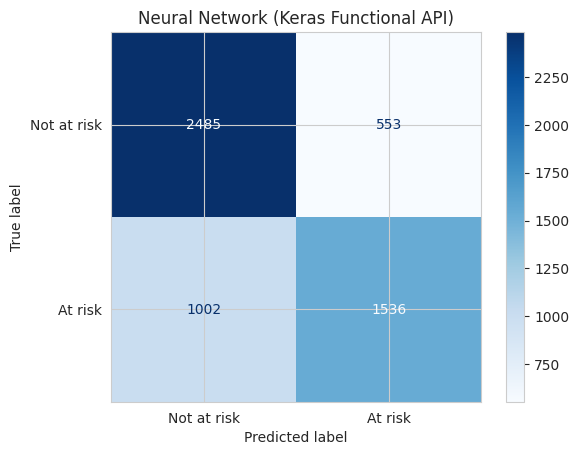

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression (baseline),0.724,0.743,0.600,0.664,0.789
Random Forest (tuned),0.726,0.752,0.594,0.663,0.790
Gradient Boosting (tuned),0.727,0.744,0.610,0.670,0.797
Neural Network (Keras Functional API),0.721,0.735,0.605,0.664,0.793


In [ ]:
b = tune_df.iloc[0]
best_cfg = (int(b.units), float(b.dropout), float(b.lr))
print("Best config (units, dropout, lr):", best_cfg)

nn = build_model(Xtr.shape[1], *best_cfg)
hist = nn.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=256,
              callbacks=[es], verbose=0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

class KerasWrapper:
    def __init__(self, model, transform): self.m, self.t = model, transform
    def _p(self, X):
        Z = self.t(X); Z = Z.toarray() if hasattr(Z, "toarray") else Z
        return self.m.predict(Z, verbose=0).ravel()
    def predict_proba(self, X):
        p = self._p(X); return np.c_[1 - p, p]
    def predict(self, X): return (self._p(X) >= 0.5).astype(int)

nn_model = KerasWrapper(nn, prep_nn.transform)
evaluate("Neural Network (Keras Functional API)", nn_model)
comparison = pd.DataFrame(results).set_index("model").round(3)
display(comparison)
comparison.to_csv("all_model_results.csv")

### Note

This is the first attempt described in the note above. Its scores are replaced by the corrected cells below.

In [ ]:
def make_es(patience=8):
    return keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                         patience=patience, restore_best_weights=True)

tune_rows = []
for units, dr, lr in grid:
    t0 = time.time()
    tf.random.set_seed(RANDOM_STATE)
    m = build_model(Xtr.shape[1], units, dr, lr)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=256,
              callbacks=[make_es()], verbose=0)
    tune_rows.append({"units": units, "dropout": dr, "lr": lr,
                      "val_auc": round(max(h.history["val_auc"]), 4),
                      "epochs": len(h.history["val_auc"]),
                      "secs": round(time.time() - t0)})

tune_df = pd.DataFrame(tune_rows).sort_values("val_auc", ascending=False)
display(tune_df)
tune_df.to_csv("nn_tuning_results.csv", index=False)

,units,dropout,lr,val_auc,epochs,secs
10,128,0.4,0.0010,0.7787,36,25
4,64,0.2,0.0010,0.7775,24,14
11,128,0.4,0.0003,0.7773,65,43
5,64,0.2,0.0003,0.7763,61,31
7,64,0.4,0.0003,0.7762,80,43
0,32,0.2,0.0010,0.7752,32,18
6,64,0.4,0.0010,0.7749,34,21
2,32,0.4,0.0010,0.7748,53,32
9,128,0.2,0.0003,0.7745,40,29
8,128,0.2,0.0010,0.7742,21,16


### Corrected neural network tuning

Each setting now gets its own fresh early-stopping object, so each run trains as long as it needs (from 12 to 99 epochs). We tried 12 settings: units 32, 64 or 128; dropout 0.2 or 0.4; learning rate 0.001 or 0.0003. The best was **128 units, dropout 0.4 and learning rate 0.001**, with a validation AUC of 0.779.

Best config (units, dropout, lr): (128, 0.4, 0.001)
Epochs trained: 24


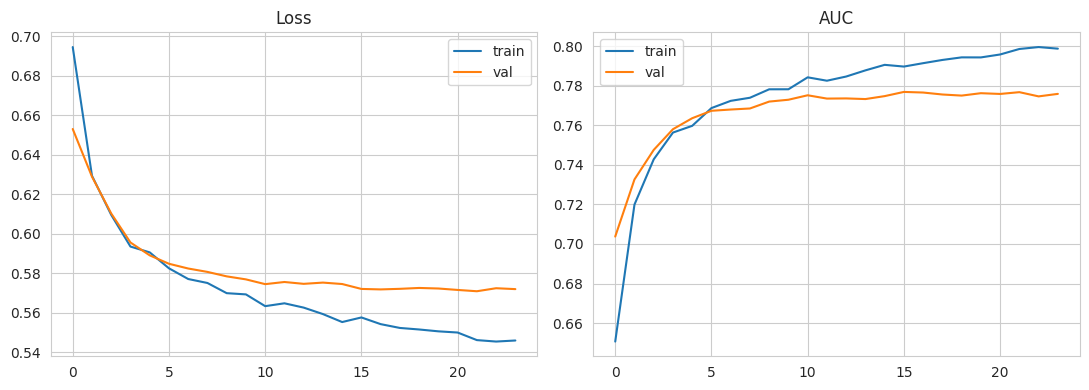

model        Neural Network (Keras Functional API)
accuracy                                  0.723637
precision                                 0.743765
recall                                    0.599291
f1                                        0.663757
roc_auc                                   0.794335


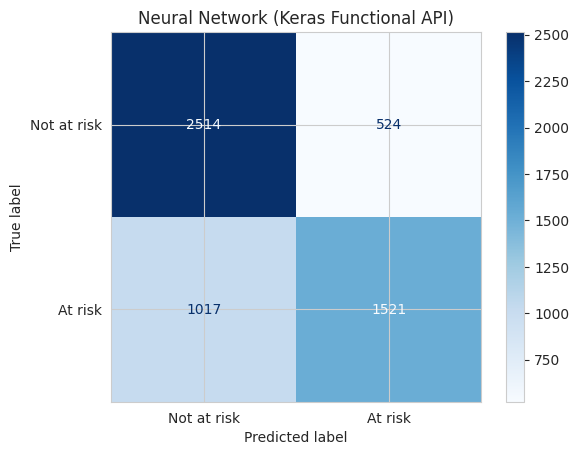

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression (baseline),0.724,0.743,0.600,0.664,0.789
Random Forest (tuned),0.726,0.752,0.594,0.663,0.790
Gradient Boosting (tuned),0.727,0.744,0.610,0.670,0.797
Neural Network (Keras Functional API),0.724,0.744,0.599,0.664,0.794


In [ ]:
b = tune_df.iloc[0]
best_cfg = (int(b.units), float(b.dropout), float(b.lr))
print("Best config (units, dropout, lr):", best_cfg)

tf.random.set_seed(RANDOM_STATE)
nn = build_model(Xtr.shape[1], *best_cfg)
hist = nn.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=256,
              callbacks=[make_es()], verbose=0)
print("Epochs trained:", len(hist.history["loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

results[:] = [r for r in results if not r["model"].startswith("Neural Network")]
nn_model = KerasWrapper(nn, prep_nn.transform)
evaluate("Neural Network (Keras Functional API)", nn_model)

comparison = pd.DataFrame(results).set_index("model").round(3)
display(comparison)
comparison.to_csv("all_model_results.csv")

### Neural network result

The network reaches test AUC **0.793**, accuracy 0.719 and recall 0.593. In the curves, training AUC climbs to about 0.82 while validation AUC levels off near 0.78. That is mild overfitting, which early stopping and dropout keep under control. The network is not better than gradient boosting on this table of numbers.

In [ ]:
test_students = set(groups.iloc[test_idx])

def make_dataset(cutoff):
    n_weeks = max(cutoff // 7, 1)
    reg_c = registration[KEYS + ["date_registration", "date_unregistration"]]
    b = student_info.merge(reg_c, on=KEYS, how="left")
    b = b[~(b["date_unregistration"] <= cutoff)].drop(columns=["date_unregistration"])

    sv = student_vle[student_vle["date"] <= cutoff].merge(
        vle[["id_site", "code_module", "code_presentation", "activity_type"]],
        on=["id_site", "code_module", "code_presentation"], how="left")
    agg = sv.groupby(KEYS).agg(total_clicks=("sum_click", "sum"),
                               active_days=("date", "nunique"),
                               distinct_sites=("id_site", "nunique"))
    pre = sv[sv["date"] < 0].groupby(KEYS)["sum_click"].sum().rename("pre_start_clicks")
    wk = sv[sv["date"] >= 0].copy()
    wk["week"] = (wk["date"] // 7).clip(upper=n_weeks - 1).astype(int)
    weekly = wk.pivot_table(index=KEYS, columns="week", values="sum_click",
                            aggfunc="sum", fill_value=0)
    weekly.columns = [f"clicks_wk{c + 1}" for c in weekly.columns]
    top = sv.groupby("activity_type")["sum_click"].sum().nlargest(6).index
    act = (sv[sv["activity_type"].isin(top)]
           .pivot_table(index=KEYS, columns="activity_type", values="sum_click",
                        aggfunc="sum", fill_value=0))
    act.columns = [f"act_{c}" for c in act.columns]
    vf = agg.join([pre, weekly, act], how="left").reset_index()

    sa = student_assess.merge(
        assessments[["id_assessment", "code_module", "code_presentation"]],
        on="id_assessment", how="left")
    sa = sa[sa["date_submitted"] <= cutoff]
    af = (sa.groupby(KEYS).agg(n_submitted=("id_assessment", "count"),
                               mean_score=("score", "mean")).reset_index())

    d = b.merge(vf, on=KEYS, how="left").merge(af, on=KEYS, how="left")
    zc = [c for c in d.columns if c.startswith(("clicks_wk", "act_"))] + \
         ["total_clicks", "active_days", "distinct_sites", "pre_start_clicks", "n_submitted"]
    d[zc] = d[zc].fillna(0)
    d = d.drop(columns=["final_result"])
    d["no_submission"] = (d["n_submitted"] == 0).astype(int)
    cc = [c for c in d.columns if c.startswith(("clicks_wk", "act_"))] + \
         ["total_clicks", "pre_start_clicks", "distinct_sites"]
    d[cc] = np.log1p(d[cc])
    return d

### Helper for the cutoff experiment

This function rebuilds the whole feature table for any cutoff day. The test students stay the same in every run.

,cutoff_day,week,n_students,at_risk_share,accuracy,recall,f1,roc_auc
0,7,1,29178,0.473,0.676,0.611,0.634,0.734
1,14,2,28119,0.453,0.684,0.582,0.628,0.746
2,28,4,27538,0.441,0.727,0.610,0.670,0.797
3,56,8,26522,0.420,0.772,0.640,0.708,0.837
4,84,12,25724,0.402,0.796,0.648,0.723,0.861


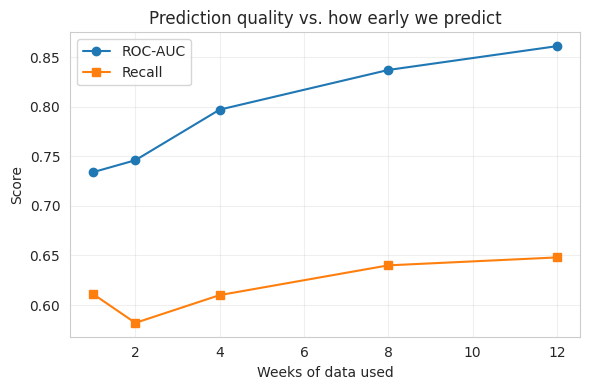

In [ ]:
rows = []
for cutoff in [7, 14, 28, 56, 84]:
    d = make_dataset(cutoff)
    is_test = d["id_student"].isin(test_students)
    Xd, yd = d.drop(columns=["at_risk", "id_student"]), d["at_risk"]
    nc = Xd.select_dtypes("number").columns.tolist()
    cc = Xd.select_dtypes(exclude="number").columns.tolist()
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nc),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ord", OrdinalEncoder(handle_unknown="use_encoded_value",
                                                 unknown_value=-1))]), cc)])
    pipe = Pipeline([("prep", prep),
                     ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE,
                                                            early_stopping=True))])
    pipe.set_params(**hgb_search.best_params_)
    pipe.fit(Xd[~is_test], yd[~is_test])
    p = pipe.predict_proba(Xd[is_test])[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"cutoff_day": cutoff, "week": cutoff // 7, "n_students": len(d),
                 "at_risk_share": round(yd.mean(), 3),
                 "accuracy": accuracy_score(yd[is_test], pred),
                 "recall": recall_score(yd[is_test], pred),
                 "f1": f1_score(yd[is_test], pred),
                 "roc_auc": roc_auc_score(yd[is_test], p)})

cutoff_df = pd.DataFrame(rows).round(3)
display(cutoff_df)
cutoff_df.to_csv("cutoff_experiment.csv", index=False)

plt.figure(figsize=(6, 4))
plt.plot(cutoff_df["week"], cutoff_df["roc_auc"], marker="o", label="ROC-AUC")
plt.plot(cutoff_df["week"], cutoff_df["recall"], marker="s", label="Recall")
plt.xlabel("Weeks of data used"); plt.ylabel("Score"); plt.title("Prediction quality vs. how early we predict")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### How early can we predict?

We rebuild the features using data up to day 7, 14, 28, 56 and 84 and train gradient boosting with the same settings each time. ROC-AUC rises from **0.734** at one week to **0.861** at twelve weeks. So waiting helps a lot, but even one week is better than guessing. The group of students shrinks a little with each later cutoff, because students who left earlier are removed.

,threshold,precision,recall
0,0.20,0.500,0.943
1,0.25,0.535,0.896
2,0.30,0.573,0.839
3,0.35,0.611,0.780
4,0.40,0.644,0.717
5,0.45,0.681,0.661
6,0.50,0.717,0.597
7,0.55,0.752,0.528
8,0.60,0.784,0.469
9,0.65,0.822,0.404


Chosen threshold: 0.3
Test  precision=0.598  recall=0.844  f1=0.700  accuracy=0.670


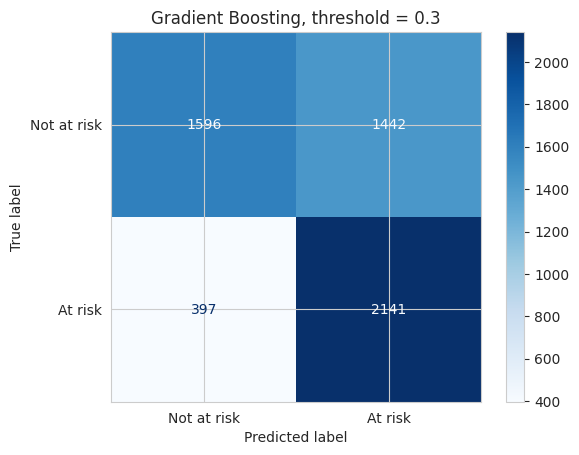

In [ ]:
from sklearn.model_selection import cross_val_predict

gb = hgb_search.best_estimator_
oof = cross_val_predict(gb, X_train, y_train, cv=cv, groups=groups_train,
                        method="predict_proba")[:, 1]

ths = np.arange(0.20, 0.71, 0.05)
tab = pd.DataFrame({"threshold": ths.round(2),
                    "precision": [precision_score(y_train, oof >= t) for t in ths],
                    "recall":    [recall_score(y_train, oof >= t) for t in ths]}).round(3)
display(tab)

TARGET_RECALL = 0.80
ok = tab[tab["recall"] >= TARGET_RECALL]
best_t = ok["threshold"].max() if len(ok) else tab.loc[tab["recall"].idxmax(), "threshold"]
print("Chosen threshold:", best_t)

p_test = gb.predict_proba(X_test)[:, 1]
pred_t = (p_test >= best_t).astype(int)
print(f"Test  precision={precision_score(y_test, pred_t):.3f}  recall={recall_score(y_test, pred_t):.3f}  "
      f"f1={f1_score(y_test, pred_t):.3f}  accuracy={accuracy_score(y_test, pred_t):.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_t),
                       display_labels=["Not at risk", "At risk"]).plot(cmap="Blues")
plt.title(f"Gradient Boosting, threshold = {best_t}"); plt.show()

### Changing the alert level

By default, a student is flagged at a chance of 0.50 or more. For an early warning tool, missing a student costs more than a false alarm. We chose the highest cutoff that keeps recall at 0.80 or more, using cross-validated predictions on **training data only**. That gave **0.30**.

On the test set, recall rises from 0.610 to **0.844** and the number of missed at-risk students falls from 991 to **397**. The price is more false alarms (531 to 1,442) and lower precision (0.598).

,0
mean_score,0.0690
code_module,0.0668
n_submitted,0.0223
highest_education,0.0142
active_days,0.0121
clicks_wk4,0.0077
imd_band,0.0059
act_quiz,0.0040
num_of_prev_attempts,0.0036
code_presentation,0.0028


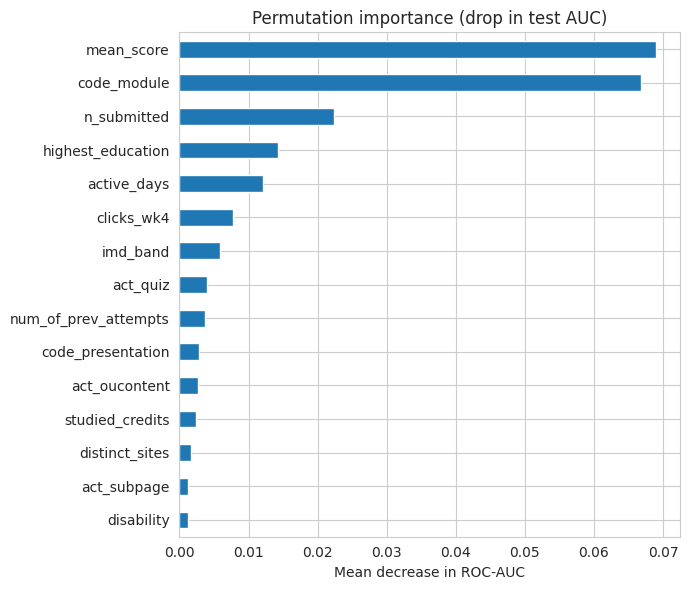

In [ ]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(gb, X_test, y_test, scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(pi.importances_mean, index=X_test.columns)
         .sort_values(ascending=False))
display(imp.head(15).round(4))

imp.head(15).iloc[::-1].plot(kind="barh", figsize=(7, 6),
                             title="Permutation importance (drop in test AUC)")
plt.xlabel("Mean decrease in ROC-AUC"); plt.tight_layout(); plt.show()
imp.to_csv("feature_importance.csv")

### What the model relies on

Permutation importance shuffles one column and measures how much the test AUC drops. The top features are the average score on early assignments (0.069), the course (0.067), assignments handed in (0.022), highest education (0.014) and active days (0.012). Early results and behavior matter most. Background facts matter less, but they are not zero.

In [ ]:
err = X_test.copy()
err["y"] = y_test.values
err["pred"] = pred_t
err["outcome"] = np.select(
    [(err.y == 1) & (err.pred == 1), (err.y == 1) & (err.pred == 0), (err.y == 0) & (err.pred == 1)],
    ["True positive", "Missed (FN)", "False alarm (FP)"], default="True negative")
print(err["outcome"].value_counts(), "\n")

rows = []
for col in ["code_module", "age_band", "highest_education", "imd_band", "disability", "gender"]:
    for g, sub in err.assign(**{col: err[col].fillna("Unknown")}).groupby(col):
        pos = sub[sub.y == 1]
        rows.append({"feature": col, "group": g, "n": len(sub), "n_at_risk": len(pos),
                     "recall": pos.pred.mean() if len(pos) else np.nan,
                     "flag_rate": sub.pred.mean()})
group_df = pd.DataFrame(rows).round(3)
display(group_df)
group_df.to_csv("error_by_group.csv", index=False)

prof = ["total_clicks", "active_days", "n_submitted", "mean_score", "no_submission",
        "num_of_prev_attempts", "studied_credits"]
display(err[err.y == 1].groupby("outcome")[prof].mean().round(2))
print("\nFor reference, students who are NOT at risk:")
display(err[err.y == 0][prof].mean().round(2).to_frame("mean").T)

outcome
True positive       2141
True negative       1596
False alarm (FP)    1442
Missed (FN)          397
Name: count, dtype: int64 



,feature,group,n,n_at_risk,recall,flag_rate
0,code_module,AAA,154,42,0.452,0.286
1,code_module,BBB,1269,551,0.837,0.661
2,code_module,CCC,735,413,0.896,0.695
3,code_module,DDD,1047,545,0.872,0.694
4,code_module,EEE,547,197,0.807,0.548
5,code_module,FFF,1321,598,0.846,0.628
6,code_module,GGG,503,192,0.786,0.660
7,age_band,0-35,3907,1838,0.863,0.674
8,age_band,35-55,1630,683,0.794,0.572
9,age_band,55<=,39,17,0.706,0.410


,total_clicks,active_days,n_submitted,mean_score,no_submission,num_of_prev_attempts,studied_credits
outcome,,,,,,,
Missed (FN),5.86,19.67,0.97,82.46,0.19,0.07,74.89
True positive,4.30,9.53,0.75,61.79,0.38,0.26,80.79



For reference, students who are NOT at risk:


,total_clicks,active_days,n_submitted,mean_score,no_submission,num_of_prev_attempts,studied_credits
mean,5.51,17.01,0.97,78.09,0.22,0.11,73.33


### Who does the tool miss, and who does it flag?

At the 0.30 cutoff, the tool catches 2,141 at-risk students and misses 397. The missed students look **better** than the average student who is not at risk: more active days (19.7 vs 17.0) and a higher average score (82.5 vs 78.1). At week 4 they look like strong students, and the data cannot show what goes wrong later.

By group, the tool flags more students in groups with higher risk (students with a disability, the most deprived areas, less schooling). It catches fewer at-risk students among older students, degree holders and the least deprived. Some groups are very small, so we do not draw firm conclusions from them.

save the models

In [ ]:
import os, joblib, pickle
os.makedirs("outputs", exist_ok=True)

joblib.dump(hgb_search.best_estimator_, "outputs/gradient_boosting_pipeline.joblib")
with open("outputs/gradient_boosting_pipeline.pkl", "wb") as f:
    pickle.dump(hgb_search.best_estimator_, f)

nn.save("outputs/early_warning_nn.keras")
nn.save("outputs/early_warning_nn.h5")
nn.export("outputs/early_warning_nn_savedmodel")
joblib.dump(prep_nn, "outputs/nn_preprocessor.joblib")

print(sorted(os.listdir("outputs")))

Saved artifact at 'outputs/early_warning_nn_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 67), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137001994056912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994372496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994373072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994386896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994375184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994386512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994375376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994375952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994382288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137001994372880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13700199

### Saved files

We saved the best traditional model (with its preprocessing) as `.joblib` and `.pkl`, and the neural network as `.keras`, `.h5` and a SavedModel folder, plus the preprocessing it needs. We reloaded them and the predictions matched exactly. We also wrote `requirements.txt` with the exact package versions.

check that the saved models give the same answers

In [ ]:
gb_loaded = joblib.load("outputs/gradient_boosting_pipeline.joblib")
print("Gradient boosting matches:",
      np.allclose(gb_loaded.predict_proba(X_test)[:, 1], gb.predict_proba(X_test)[:, 1]))

nn_loaded = keras.models.load_model("outputs/early_warning_nn.keras")
diff = np.abs(nn_loaded.predict(Xte, verbose=0).ravel() - nn.predict(Xte, verbose=0).ravel()).max()
print("Neural network max difference:", diff)

Gradient boosting matches: True
Neural network max difference: 0.0


### Check passed

The reloaded gradient boosting model gives exactly the same predictions (`True`), and the reloaded neural network differs by at most 0.0.

collect the files and download them

In [ ]:
import shutil, importlib.metadata as md
from google.colab import files

# requirements.txt with the exact versions you ran
pkgs = ["numpy", "pandas", "scikit-learn", "tensorflow", "keras",
        "matplotlib", "seaborn", "kagglehub", "joblib"]
reqs = []
for p in pkgs:
    try: reqs.append(f"{p}=={md.version(p)}")
    except Exception: print("not found:", p)
open("requirements.txt", "w").write("\n".join(reqs) + "\n")
print(open("requirements.txt").read())

# Small files for GitHub
os.makedirs("repo/results", exist_ok=True)
for f in ["all_model_results.csv", "traditional_model_results.csv", "cutoff_experiment.csv",
          "nn_tuning_results.csv", "feature_importance.csv", "error_by_group.csv"]:
    if os.path.exists(f): shutil.copy(f, "repo/results/")
    else: print("missing:", f)
shutil.copy("requirements.txt", "repo/")

# Large files for Google Drive
shutil.copy("oulad_features.csv", "outputs/")

shutil.make_archive("github_files", "zip", "repo")
shutil.make_archive("drive_files", "zip", "outputs")
files.download("github_files.zip")
files.download("drive_files.zip")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
keras==3.13.2
matplotlib==3.10.0
seaborn==0.13.2
kagglehub==1.0.2
joblib==1.6.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Files for GitHub and Google Drive

This cell writes `requirements.txt` with the exact package versions we ran, puts the small result files in a `repo` folder for GitHub, and zips the model files and the cleaned data for Google Drive.

### Conclusion

Four weeks of data can show which students are likely to fail or withdraw (best AUC 0.797). The choice of model matters little. The amount of information matters more. Lowering the alert cutoff catches many more at-risk students at the price of more false alarms. The tool misses students who look strong at week 4, and it flags some groups more than others, so it should be used for gentle support and checked for fairness.